# 03. Statistical Analysis, Decision Protocol, and Plots

**Course**: CS 328 — Introduction to Data Science  
**Project**: *Does Graph-Based Retrieval Beat Vector Search on Multi-Hop Questions?*  

This notebook presents the definitive statistical analysis:
- Primary hypothesis test on **recall@5** (Paired Bootstrap 95% CI & 100,000 Sign-Flip Permutations)
- Pre-Registered 3-way decision protocol verdict
- Holm-Bonferroni Family-Wise Error Rate (FWER) control for secondary metrics
- Confirmatory relational chain contrast ($ sub-claim)
- Downstream QA accuracy (Exact Match, Token F1, Closed-Book floor & Oracle ceiling)
- Publication-ready figures

In [1]:
import sys
import json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display
from src import config

results_path = config.RESULTS_DIR / "experiment_results.json"
with open(results_path, "r") as f:
    res = json.load(f)

print("=== PRE-REGISTERED EXPERIMENTAL VERDICT ===")
print(res["verdict"])

=== PRE-REGISTERED EXPERIMENTAL VERDICT ===
BRANCH 1: REJECT H0 IN FAVOR OF H1 (GRAPH SIGNIFICANTLY SUPERIOR)
The observed recall@5 gain (Delta = +26.62%) is positive and statistically significant at alpha=0.05 (95% Paired Bootstrap CI: [22.38%, 30.63%], Sign-Flip Permutation p = 0.00000). Random walks on the entity graph provide superior multi-hop retrieval over standard dense vector search.


## 1. Primary Retrieval Comparison (recall@5)

Vector Baseline recall@5: 67.12%
Graph + PPR     recall@5: 93.75%
Observed Gain (Delta):    +26.62%
95% Paired Bootstrap CI:  [22.38%, 30.63%]
Permutation Test p-value: 0.00000


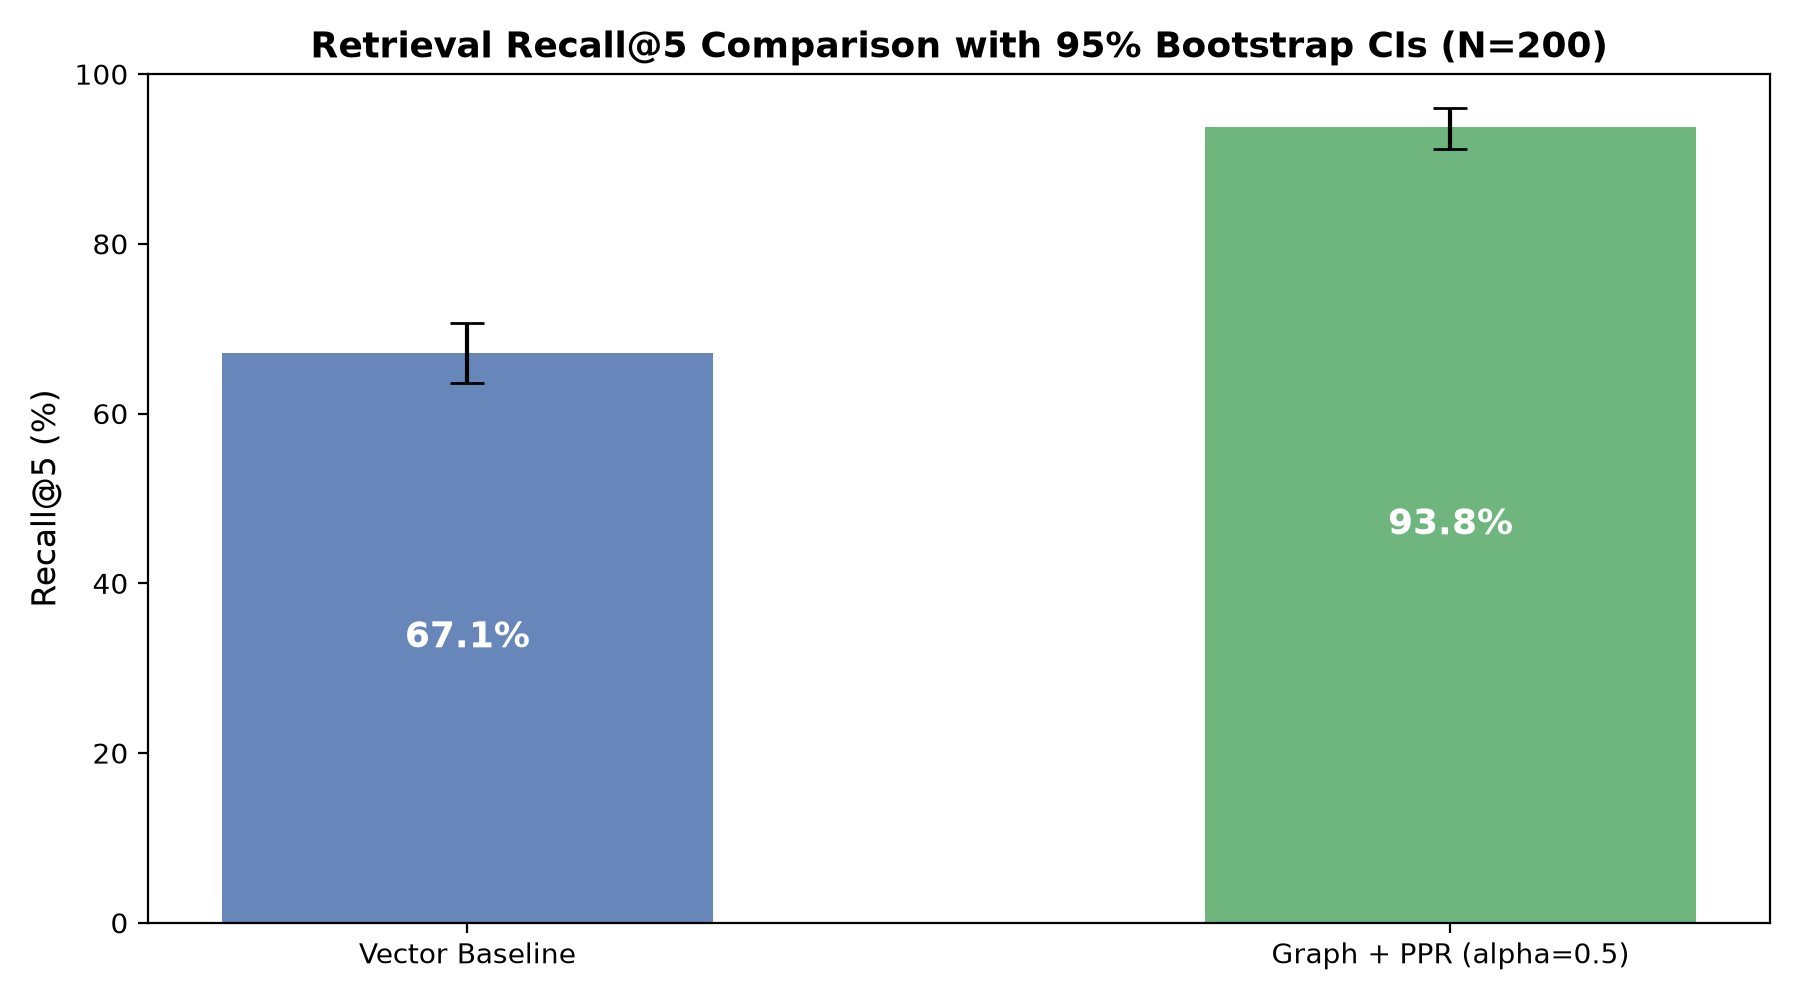

In [2]:
r5_data = res["retrieval_metrics"]["recall@5"]
print(f"Vector Baseline recall@5: {r5_data['vector_mean']*100:.2f}%")
print(f"Graph + PPR     recall@5: {r5_data['graph_mean']*100:.2f}%")
print(f"Observed Gain (Delta):    {res['delta_r5']*100:+.2f}%")
print(f"95% Paired Bootstrap CI:  [{res['ci_r5'][0]*100:.2f}%, {res['ci_r5'][1]*100:.2f}%]")
print(f"Permutation Test p-value: {res['p_perm_r5']:.5f}")

display(Image(filename=str(config.FIGURES_DIR / "recall_comparison.png")))

## 2. Secondary Tests with Holm-Bonferroni FWER Control

In [3]:
sec_df = pd.DataFrame(res["secondary_tests"]).T
print(sec_df)

                     rank    raw_p threshold significant
recall@2_gain           1      0.0    0.0125        True
no_walk_control         2      0.0  0.016667        True
all-recall@5_mcnemar    3      0.0     0.025        True
damping_sensitivity     4  0.63413      0.05       False


## 3. Question-Level Scatter Plot & Strata Breakdown

Per-Stratum Retrieval Recall@5:
                   count  graph_recall@5  vector_recall@5  delta_recall@5
compositional       83.0        0.945783         0.608434        0.337349
inference           25.0        0.900000         0.720000        0.180000
comparison          48.0        1.000000         0.916667        0.083333
bridge_comparison   44.0        0.875000         0.494318        0.380682


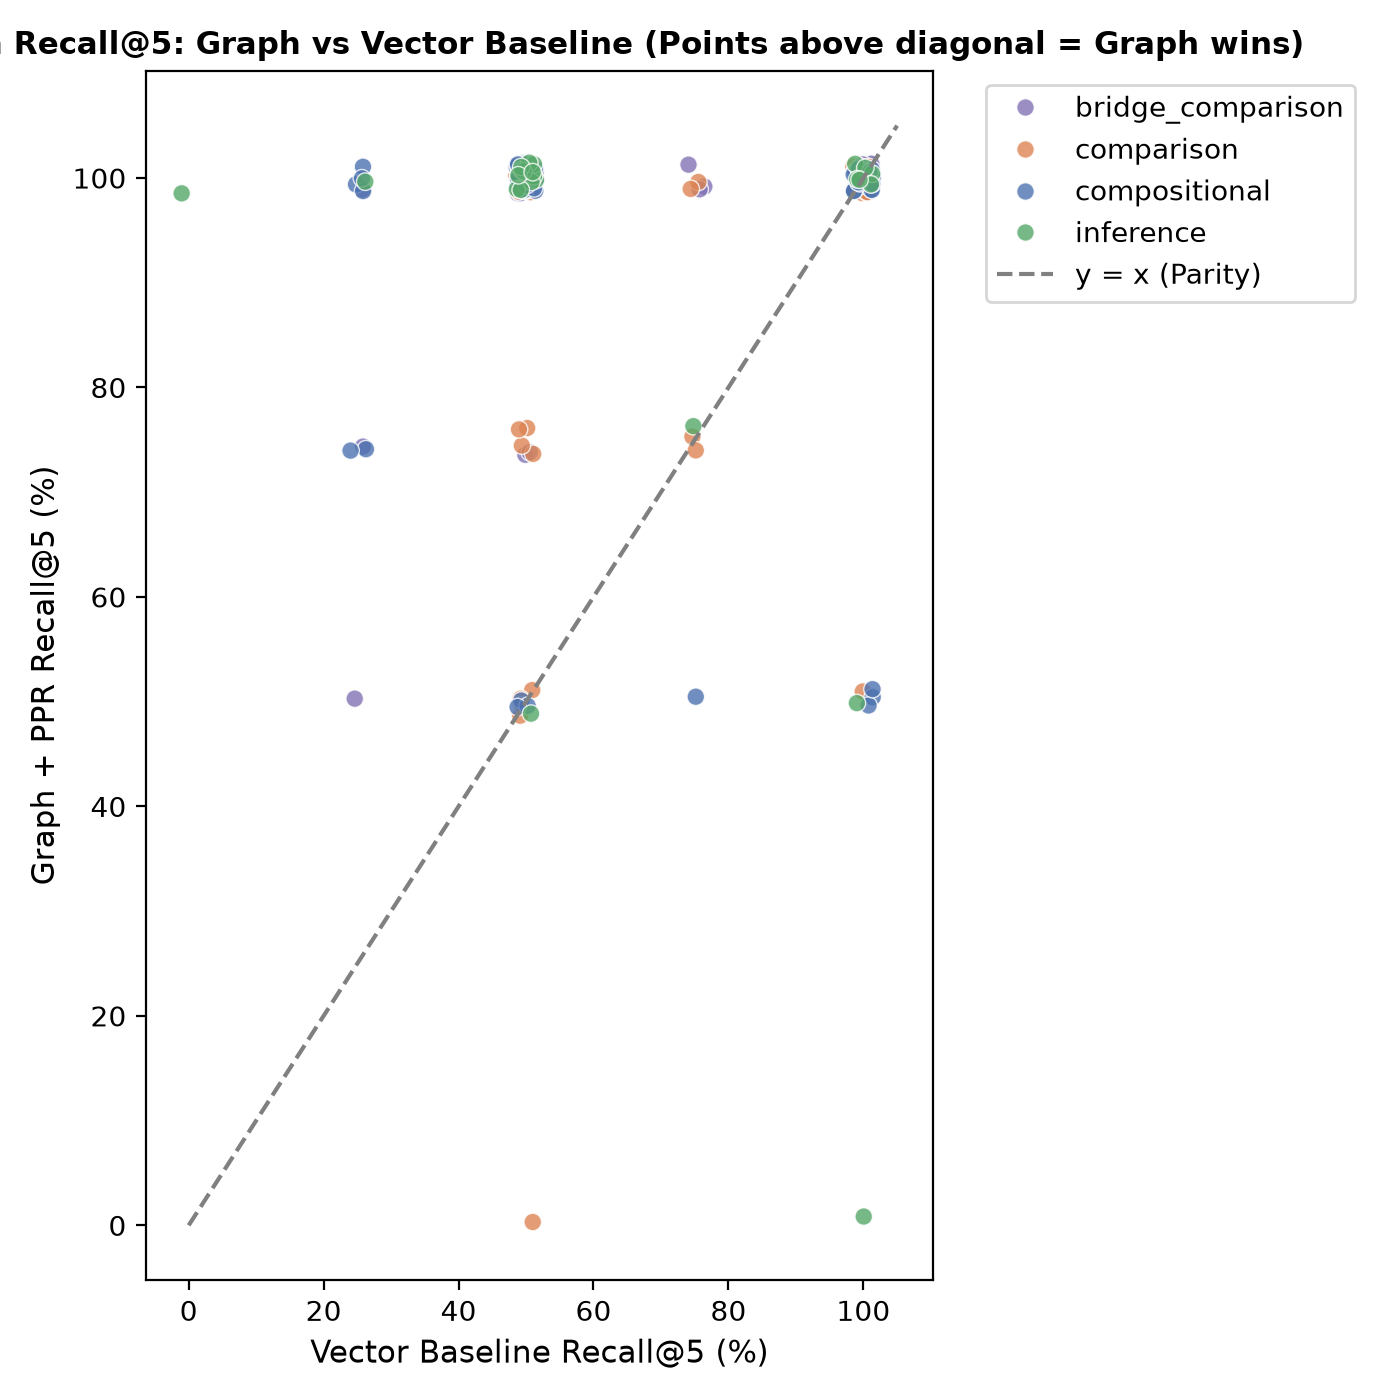

In [4]:
strata_df = pd.DataFrame(res["retrieval_metrics"]["strata"]).T
print("Per-Stratum Retrieval Recall@5:")
print(strata_df)

display(Image(filename=str(config.FIGURES_DIR / "per_question_scatter.png")))

## 4. Downstream Reading Comprehension (RQ2: EM & F1)

In [5]:
qa_df = pd.DataFrame(res["reader_metrics"]).T
qa_df["exact_match"] = (qa_df["exact_match"] * 100).round(2)
qa_df["f1"] = (qa_df["f1"] * 100).round(2)
print("Downstream QA Metrics (%):")
print(qa_df)

Downstream QA Metrics (%):
        exact_match    f1
vector         88.0  88.0
graph          96.0  96.0
oracle         96.0  96.0
closed         96.0  96.0
